# 03 — Analyse de survie : Kaplan-Meier et modèle de Cox

**Projet Horizon : décrochage et tutorat** — tâches SV-01 (Kaplan-Meier, log-rank, semaines critiques) et SV-02 (modèle de Cox).

Ce notebook lit `data/processed/base_survie.csv` (il ne relance pas le pipeline) ; les calculs sont dans `src/survie.py`.
Seules les variables connues à la rentrée sont utilisées (D-43) : **aucune variable de tutorat**, qui relève de la partie causale.

Décisions appliquées : D-46 (sous-groupes, Bonferroni), D-47 (semaine critique), D-48 (Cox sur les 5 000 étudiants), D-49 (variables), D-50 (valeurs manquantes), D-51 (proportionnalité des risques).

> **Ces résultats sont des associations, pas des effets.** Par exemple, si les boursiers décrochent moins souvent, cela ne veut pas dire que la bourse les fait rester : les boursiers peuvent différer des autres étudiants sur bien d'autres points que ce modèle ne mesure pas.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import NullFormatter, PercentFormatter

# Le notebook est dans notebooks/ : on remonte jusqu'à la racine du dépôt (dossier qui
# contient src/config.py) pour pouvoir importer src/, quel que soit le dossier de lancement.
racine = Path.cwd()
while not (racine / "src" / "config.py").exists():
    racine = racine.parent
sys.path.insert(0, str(racine))

from src import config, survie

# lifelines signale des avertissements de convergence sans gravité sur les petits groupes.
warnings.filterwarnings("ignore", module="lifelines")
pd.set_option("display.width", 160)
config.DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)


def enregistrer(figure, nom):
    """Enregistre une figure en PNG dans docs/figures/ et l'affiche."""
    figure.tight_layout()
    figure.savefig(config.DOSSIER_FIGURES / nom, dpi=120)
    plt.show()


def nombre(x, decimales=1):
    """Nombre au format français, ex. 85,3."""
    return f"{x:.{decimales}f}".replace(".", ",")


def valeur_p(p):
    """p-valeur lisible : 0,012 ou 2,1e-06."""
    return nombre(p, 3) if p >= 0.001 else f"{p:.1e}".replace(".", ",")


base = survie.lire_base()
print(f"{len(base)} étudiants, dont {int(base['E'].sum())} décrochages observés (E = 1).")

5000 étudiants, dont 1440 décrochages observés (E = 1).


## 1. Courbe de survie globale (Kaplan-Meier)

La « survie » S(t) est ici la part des étudiants **qui n'ont pas encore décroché** après t semaines. Kaplan-Meier tient compte de la censure : un étudiant transféré ou perdu de vue compte tant qu'on le suit, puis sort du calcul sans être compté comme décrocheur.

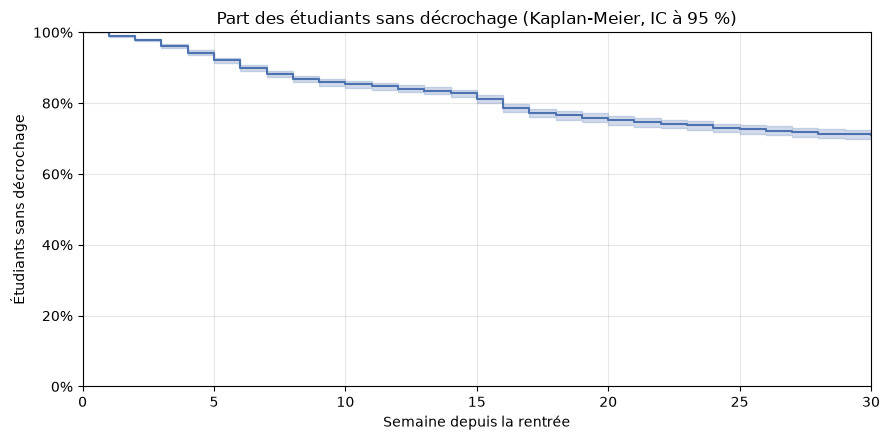

,semaine,survie,ic_bas,ic_haut
0,10,0.853,0.843,0.862
1,20,0.752,0.740,0.764
2,30,0.709,0.696,0.722


Après 10 semaines, 85,3 % des étudiants n'ont pas décroché (IC à 95 % : 84,3 à 86,2 %) ; après 20 semaines, 75,2 % ; à la fin du suivi (30 semaines), 70,9 % (IC : 69,6 à 72,2 %). Autrement dit, environ 29 % des étudiants décrochent pendant les 30 semaines.
La durée médiane avant décrochage n'est pas atteinte : la courbe ne descend jamais sous 50 %, car plus de la moitié des étudiants n'ont pas décroché à la fin du suivi.


In [2]:
global_ = survie.kaplan_meier_global(base)
figure, axe = plt.subplots(figsize=(9, 4.5))
global_["kmf"].plot_survival_function(ax=axe, ci_show=True, color="#4C72B0")
axe.set_ylim(0, 1)
axe.yaxis.set_major_formatter(PercentFormatter(1))
axe.set_xlim(0, config.N_SEMAINES)
axe.set_title("Part des étudiants sans décrochage (Kaplan-Meier, IC à 95 %)")
axe.set_xlabel("Semaine depuis la rentrée")
axe.set_ylabel("Étudiants sans décrochage")
axe.get_legend().remove()
axe.grid(alpha=0.3)
enregistrer(figure, "03_km_global.png")

survies = global_["survies"]
display(survies.round(3))
s = survies.set_index("semaine")
print(f"Après 10 semaines, {nombre(100 * s.loc[10, 'survie'])} % des étudiants n'ont pas décroché "
      f"(IC à 95 % : {nombre(100 * s.loc[10, 'ic_bas'])} à {nombre(100 * s.loc[10, 'ic_haut'])} %) ; "
      f"après 20 semaines, {nombre(100 * s.loc[20, 'survie'])} % ; à la fin du suivi (30 semaines), "
      f"{nombre(100 * s.loc[30, 'survie'])} % (IC : {nombre(100 * s.loc[30, 'ic_bas'])} à {nombre(100 * s.loc[30, 'ic_haut'])} %). "
      "Autrement dit, environ " + nombre(100 * (1 - s.loc[30, 'survie']), 0) + " % des étudiants décrochent pendant les 30 semaines.")
if global_["mediane"] is None:
    print("La durée médiane avant décrochage n'est pas atteinte : la courbe ne descend jamais sous 50 %, "
          "car plus de la moitié des étudiants n'ont pas décroché à la fin du suivi.")
else:
    print(f"La moitié des étudiants ont décroché après {global_['mediane']:.0f} semaines.")

## 2. Risque hebdomadaire et semaines critiques

Risque de la semaine s = décrochages de la semaine / étudiants encore suivis au début de la semaine (avec son IC à 95 %). **Semaine critique** (D-47) : risque au moins 1,5 fois plus élevé que le risque hebdomadaire moyen.

,semaine,suivis,decrochages,risque (%),IC bas (%),IC haut (%),critique
0,1,5000,46,0.92,0.66,1.18,False
1,2,4951,61,1.23,0.92,1.54,False
2,3,4884,84,1.72,1.36,2.08,False
3,4,4797,94,1.96,1.57,2.35,True
4,5,4699,106,2.26,1.83,2.68,True
5,6,4589,110,2.40,1.95,2.84,True
6,7,4478,81,1.81,1.42,2.20,True
7,8,4395,74,1.68,1.30,2.06,False
8,9,4320,47,1.09,0.78,1.40,False
9,10,4263,30,0.70,0.45,0.95,False


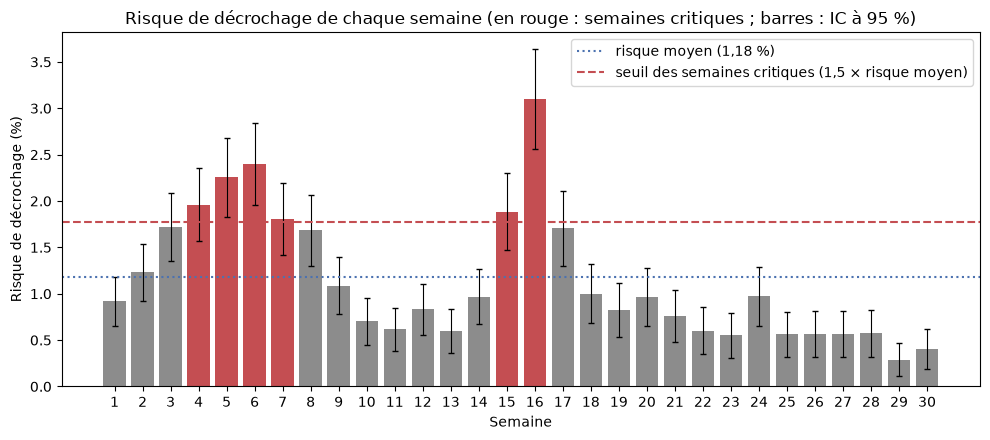

Le risque hebdomadaire moyen est de 1,18 % : chaque semaine, environ 1 étudiant encore inscrit sur 85 décroche. Les semaines critiques (risque d'au moins 1,77 %) sont les semaines 4, 5, 6, 7, 15, 16. Ce sont les semaines où le risque observé est le plus élevé : elles peuvent guider le calendrier du suivi des étudiants (début d'année et milieu d'année).


In [3]:
risque, risque_moyen = survie.risque_hebdomadaire(base)
risque = survie.marquer_semaines_critiques(risque, risque_moyen)
tableau_risque = risque[["semaine", "suivis", "decrochages", "taux", "ic_bas", "ic_haut", "critique"]].copy()
for colonne in ["taux", "ic_bas", "ic_haut"]:
    tableau_risque[colonne] = (100 * tableau_risque[colonne]).round(2)
display(tableau_risque.rename(columns={"taux": "risque (%)", "ic_bas": "IC bas (%)", "ic_haut": "IC haut (%)"}))

figure, axe = plt.subplots(figsize=(10, 4.5))
couleurs = ["#C44E52" if c else "#8C8C8C" for c in risque["critique"]]
axe.bar(risque["semaine"], 100 * risque["taux"], color=couleurs)
axe.errorbar(risque["semaine"], 100 * risque["taux"],
             yerr=[100 * (risque["taux"] - risque["ic_bas"]), 100 * (risque["ic_haut"] - risque["taux"])],
             fmt="none", ecolor="black", elinewidth=0.8, capsize=2)
axe.axhline(100 * risque_moyen, color="#4C72B0", linestyle=":", label=f"risque moyen ({nombre(100 * risque_moyen, 2)} %)")
axe.axhline(100 * risque["seuil"].iloc[0], color="#C44E52", linestyle="--",
            label=f"seuil des semaines critiques ({nombre(config.FACTEUR_SEMAINE_CRITIQUE)} × risque moyen)")
axe.set_title("Risque de décrochage de chaque semaine (en rouge : semaines critiques ; barres : IC à 95 %)")
axe.set_xlabel("Semaine")
axe.set_ylabel("Risque de décrochage (%)")
axe.set_xticks(range(1, config.N_SEMAINES + 1))
axe.legend()
enregistrer(figure, "03_risque_hebdomadaire.png")

critiques = list(risque.loc[risque["critique"], "semaine"])
print(f"Le risque hebdomadaire moyen est de {nombre(100 * risque_moyen, 2)} % : chaque semaine, environ 1 étudiant "
      f"encore inscrit sur {1 / risque_moyen:.0f} décroche. Les semaines critiques (risque d'au moins "
      f"{nombre(100 * risque['seuil'].iloc[0], 2)} %) sont les semaines {', '.join(str(s) for s in critiques)}. "
      "Ce sont les semaines où le risque observé est le plus élevé : elles peuvent guider le calendrier du suivi "
      "des étudiants (début d'année et milieu d'année).")

## 3. Courbes de survie par sous-groupe et tests du log-rank

Sous-groupes du cahier des charges (D-46) : boursier, filière, mention du bac, emploi en parallèle. Les étudiants dont la variable manque sont exclus de sa comparaison. Avec 4 tests, une différence n'est retenue que si p < 0,05 / 4 = 0,0125 (correction de Bonferroni).

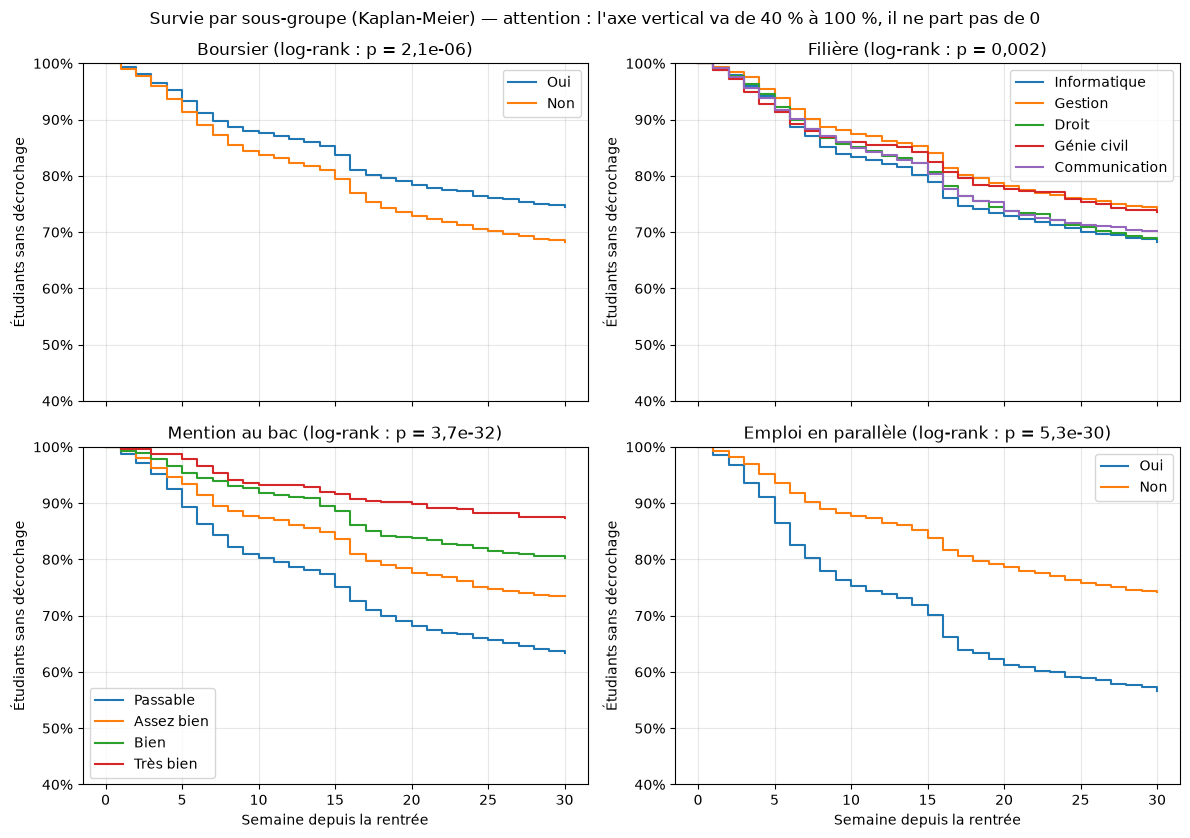

,variable,modalite,effectif,decrochages,S(10),S(20),S(30)
0,boursier,Oui,2077,524,0.875,0.784,0.745
1,boursier,Non,2923,916,0.837,0.729,0.683
2,filiere,Informatique,1438,454,0.833,0.729,0.682
3,filiere,Gestion,1236,314,0.875,0.782,0.744
4,filiere,Droit,821,253,0.851,0.737,0.687
5,filiere,Génie civil,742,194,0.860,0.777,0.736
6,filiere,Communication,763,225,0.850,0.737,0.702
7,mention_bac,Passable,2296,836,0.802,0.682,0.633
8,mention_bac,Assez bien,1476,387,0.874,0.776,0.734
9,mention_bac,Bien,901,176,0.919,0.838,0.802


,variable,groupes,manquants exclus,statistique,p brute,seuil de Bonferroni,conclusion
0,boursier,2,0,22.496058,2.105753e-06,0.0125,courbes différentes (p < seuil de Bonferroni)
1,filiere,5,0,16.616118,2.294642e-03,0.0125,courbes différentes (p < seuil de Bonferroni)
2,mention_bac,4,0,149.302119,3.726575e-32,0.0125,courbes différentes (p < seuil de Bonferroni)
3,emploi_parallele,2,200,129.478413,5.329291e-30,0.0125,courbes différentes (p < seuil de Bonferroni)


- Boursier : à 30 semaines, 74,5 % des étudiants « Oui » n'ont pas décroché, contre 68,3 % des « Non » ; log-rank p = 2,1e-06 : la différence est nette.
- Filière : à 30 semaines, 74,4 % des étudiants « Gestion » n'ont pas décroché, contre 68,2 % des « Informatique » ; log-rank p = 0,002 : la différence est nette.
- Mention au bac : à 30 semaines, 87,3 % des étudiants « Très bien » n'ont pas décroché, contre 63,3 % des « Passable » ; log-rank p = 3,7e-32 : la différence est nette.
- Emploi en parallèle (200 étudiants sans réponse exclus) : à 30 semaines, 74,2 % des étudiants « Non » n'ont pas décroché, contre 56,7 % des « Oui » ; log-rank p = 5,3e-30 : la différence est nette.
Ces différences sont des associations, observées une variable à la fois : le modèle de Cox ci-dessous les examine ensemble, à autres variables égales.


In [4]:
resultats = {v: survie.kaplan_meier_sous_groupe(base, v) for v in config.VARIABLES_KAPLAN_MEIER}
titres = {"boursier": "Boursier", "filiere": "Filière", "mention_bac": "Mention au bac",
          "emploi_parallele": "Emploi en parallèle"}
plus_basse = min(r["tableau"][f"S({config.N_SEMAINES})"].min() for r in resultats.values())
bas_axe = np.floor(10 * plus_basse - 1) / 10  # au moins 10 points sous la courbe la plus basse

figure, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharex=True)
for axe, (variable, resultat) in zip(axes.flat, resultats.items()):
    for modalite, kmf in resultat["kmfs"].items():
        kmf.plot_survival_function(ax=axe, ci_show=False)
    axe.set_ylim(bas_axe, 1)
    axe.yaxis.set_major_formatter(PercentFormatter(1))
    axe.set_title(f"{titres[variable]} (log-rank : p = {valeur_p(resultat['p'])})")
    axe.set_xlabel("Semaine depuis la rentrée")
    axe.set_ylabel("Étudiants sans décrochage")
    axe.grid(alpha=0.3)
figure.suptitle(f"Survie par sous-groupe (Kaplan-Meier) — attention : l'axe vertical va de "
                f"{nombre(100 * bas_axe, 0)} % à 100 %, il ne part pas de 0")
enregistrer(figure, "03_km_sous_groupes.png")

par_groupe = pd.concat([r["tableau"] for r in resultats.values()], ignore_index=True)
display(par_groupe.round(3))
log_rank = survie.tableau_log_rank(resultats)
log_rank["conclusion"] = np.where(log_rank["différence significative"],
                                  "courbes différentes (p < seuil de Bonferroni)", "pas de différence établie")
display(log_rank.drop(columns="différence significative"))

for variable, resultat in resultats.items():
    tableau = resultat["tableau"].sort_values(f"S({config.N_SEMAINES})")
    pire, meilleur = tableau.iloc[0], tableau.iloc[-1]
    conclusion = ("la différence est nette" if resultat["p"] < config.ALPHA / len(resultats)
                  else "la différence n'est pas établie")
    manquants = f" ({resultat['manquants']} étudiants sans réponse exclus)" if resultat["manquants"] else ""
    print(f"- {titres[variable]}{manquants} : à 30 semaines, {nombre(100 * meilleur['S(30)'])} % des étudiants « {meilleur['modalite']} » "
          f"n'ont pas décroché, contre {nombre(100 * pire['S(30)'])} % des « {pire['modalite']} » ; "
          f"log-rank p = {valeur_p(resultat['p'])} : {conclusion}.")
print("Ces différences sont des associations, observées une variable à la fois : le modèle de Cox ci-dessous "
      "les examine ensemble, à autres variables égales.")

## 4. Modèle de Cox

Variables (D-49) : genre (réf. F), âge, boursier (réf. Non), filière (réf. Informatique), note du bac, région regroupée (réf. Dakar), log2 de la distance (un hazard ratio correspond à un **doublement** de la distance), emploi (réf. Non). Valeurs manquantes (D-50) : modalité « (manquant) » pour les variables qualitatives, médiane pour les numériques. Le modèle est ajusté sur les 5 000 étudiants (D-48) ; la cohorte est traitée selon la règle de proportionnalité (section 5).

Un **hazard ratio (HR)** compare le risque instantané de décrocher : HR = 1,5 signifie un risque 1,5 fois plus élevé ; HR = 0,8, un risque 20 % plus faible, à autres variables égales.

In [5]:
donnees, medianes = survie.preparer_donnees_cox(base)
cox = survie.cox_avec_regle(donnees)
modele = cox["modele_final"]
hr = survie.hazard_ratios(modele)
display(hr.round(3))
print(f"Modèle final : {len(donnees)} étudiants, {int(donnees['E'].sum())} décrochages, "
      f"stratifié par {', '.join(cox['strates']) or 'aucune variable'} ; C-index = {nombre(modele.concordance_index_, 3)} "
      "(0,5 = pas mieux que le hasard, 1 = classement parfait des étudiants selon leur moment de décrochage).")

LIBELLES = {
    "age": "Chaque année d'âge en plus",
    "note_bac": "Chaque point de note du bac en plus",
    "log2_distance": "Un doublement de la distance au campus",
    "genre=M": "Être un homme (par rapport à une femme)",
    "boursier=Oui": "Être boursier (par rapport à non boursier)",
    "region_dakar=Hors Dakar": "Venir d'une région hors Dakar (par rapport à Dakar)",
    f"region_dakar={config.MODALITE_MANQUANTE}": "Une région d'origine inconnue (par rapport à Dakar)",
    "emploi_parallele=Oui": "Avoir un emploi en parallèle (par rapport à pas d'emploi)",
    f"emploi_parallele={config.MODALITE_MANQUANTE}": "Une situation d'emploi inconnue (par rapport à pas d'emploi)",
}


def libelle(colonne):
    """Texte lisible d'une colonne du Cox."""
    if colonne in LIBELLES:
        return LIBELLES[colonne]
    variable, modalite = colonne.split(config.SEPARATEUR_INDICATRICE)
    return f"Être en {modalite} (par rapport à {config.REFERENCES_COX[variable]})"


for colonne, ligne in hr.iterrows():
    intervalle = f"HR {nombre(ligne['HR'], 2)}, IC à 95 % {nombre(ligne['IC bas'], 2)} à {nombre(ligne['IC haut'], 2)}"
    if ligne["p"] >= config.ALPHA:
        print(f"- {libelle(colonne)} : pas d'association nette avec le décrochage ({intervalle}, p = {valeur_p(ligne['p'])}).")
    elif ligne["HR"] > 1:
        print(f"- {libelle(colonne)} : associé à un risque de décrochage {nombre(ligne['HR'], 2)} fois plus élevé, "
              f"à autres variables égales ({intervalle}).")
    else:
        print(f"- {libelle(colonne)} : associé à un risque de décrochage plus faible, multiplié par {nombre(ligne['HR'], 2)} "
              f"(environ {nombre(100 * (1 - ligne['HR']), 0)} % de moins), à autres variables égales ({intervalle}).")

,HR,IC bas,IC haut,p
variable,,,,
age,1.090,1.055,1.125,0.000
note_bac,0.838,0.813,0.863,0.000
log2_distance,1.109,1.066,1.154,0.000
genre=M,1.086,0.979,1.206,0.119
boursier=Oui,0.768,0.689,0.855,0.000
filiere=Gestion,0.775,0.671,0.895,0.001
filiere=Droit,0.959,0.822,1.119,0.597
filiere=Génie civil,0.805,0.680,0.953,0.012
filiere=Communication,0.926,0.789,1.087,0.348


Modèle final : 5000 étudiants, 1440 décrochages, stratifié par cohorte ; C-index = 0,642 (0,5 = pas mieux que le hasard, 1 = classement parfait des étudiants selon leur moment de décrochage).
- Chaque année d'âge en plus : associé à un risque de décrochage 1,09 fois plus élevé, à autres variables égales (HR 1,09, IC à 95 % 1,06 à 1,12).
- Chaque point de note du bac en plus : associé à un risque de décrochage plus faible, multiplié par 0,84 (environ 16 % de moins), à autres variables égales (HR 0,84, IC à 95 % 0,81 à 0,86).
- Un doublement de la distance au campus : associé à un risque de décrochage 1,11 fois plus élevé, à autres variables égales (HR 1,11, IC à 95 % 1,07 à 1,15).
- Être un homme (par rapport à une femme) : pas d'association nette avec le décrochage (HR 1,09, IC à 95 % 0,98 à 1,21, p = 0,119).
- Être boursier (par rapport à non boursier) : associé à un risque de décrochage plus faible, multiplié par 0,77 (environ 23 % de moins), à autres variables égales (HR 0,77, IC à 

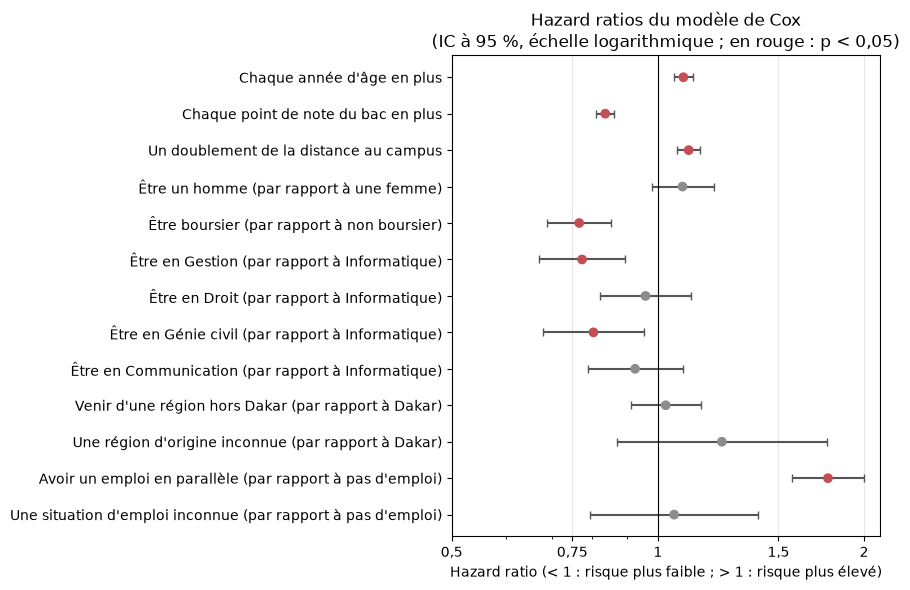

Les associations les plus marquées : « avoir un emploi en parallèle (par rapport à pas d'emploi) » (HR 1,77) du côté d'un risque plus élevé, et « être boursier (par rapport à non boursier) » (HR 0,77) du côté d'un risque plus faible. Rappel : ce sont des associations, pas des effets causaux.


In [6]:
ordre = hr.iloc[::-1]
figure, axe = plt.subplots(figsize=(9, 6))
significatif = ordre["p"] < config.ALPHA
axe.errorbar(ordre["HR"], range(len(ordre)), xerr=[ordre["HR"] - ordre["IC bas"], ordre["IC haut"] - ordre["HR"]],
             fmt="none", ecolor="#555555", capsize=3)
axe.scatter(ordre["HR"], range(len(ordre)), color=np.where(significatif, "#C44E52", "#8C8C8C"), zorder=3)
axe.axvline(1, color="black", linewidth=0.8)
axe.set_xscale("log")
axe.set_xticks([0.5, 0.75, 1, 1.5, 2])
axe.set_xticklabels(["0,5", "0,75", "1", "1,5", "2"])
axe.xaxis.set_minor_formatter(NullFormatter())
axe.set_yticks(range(len(ordre)))
axe.set_yticklabels([libelle(c) for c in ordre.index])
axe.set_title("Hazard ratios du modèle de Cox\n(IC à 95 %, échelle logarithmique ; en rouge : p < 0,05)")
axe.set_xlabel("Hazard ratio (< 1 : risque plus faible ; > 1 : risque plus élevé)")
axe.grid(alpha=0.3, axis="x")
enregistrer(figure, "03_cox_hazard_ratios.png")
plus_fort = hr["HR"].idxmax()
plus_protecteur = hr["HR"].idxmin()
print(f"Les associations les plus marquées : « {libelle(plus_fort).lower()} » (HR {nombre(hr.loc[plus_fort, 'HR'], 2)}) "
      f"du côté d'un risque plus élevé, et « {libelle(plus_protecteur).lower()} » (HR {nombre(hr.loc[plus_protecteur, 'HR'], 2)}) "
      "du côté d'un risque plus faible. Rappel : ce sont des associations, pas des effets causaux.")

## 5. Hypothèse des risques proportionnels

Le modèle de Cox suppose que le rapport des risques entre deux groupes reste le même tout au long des 30 semaines. On le vérifie par le test des résidus de Schoenfeld, variable par variable (D-51, transformation « rank »). Règle fixée avant l'analyse : si p < 0,05, une variable qualitative est mise en **strate**, une variable numérique en interaction avec la période (semaines 1 à 8 / 9 à 30).

In [7]:
avant = cox["schoenfeld_1"].set_index("colonne")[["statistique", "p"]]
apres = cox["schoenfeld_final"].set_index("colonne")[["statistique", "p"]]
comparaison = avant.join(apres, lsuffix=" (modèle 1)", rsuffix=" (modèle final)")
display(comparaison.round(3))
en_defaut = cox["schoenfeld_1"][cox["schoenfeld_1"]["p"] < config.ALPHA]
liste = ", ".join(f"{c} (p = {valeur_p(p)})" for c, p in zip(en_defaut["colonne"], en_defaut["p"]))
print(f"Dans le modèle 1 (cohorte en covariable), une seule colonne viole l'hypothèse : {liste}." if len(en_defaut) == 1
      else f"Dans le modèle 1, colonnes qui violent l'hypothèse : {liste or 'aucune'}.")
print(f"Règle appliquée : stratification par {', '.join(cox['strates']) or 'aucune variable'}. Stratifier par cohorte "
      "revient à laisser chaque cohorte avoir sa propre courbe de risque de base au fil des semaines, sans imposer "
      "un rapport constant entre elles ; les hazard ratios des autres variables restent communs aux deux cohortes. "
      f"Après stratification, aucune variable n'a p < 0,05 (p minimum : {valeur_p(apres['p'].min())}) : "
      "l'hypothèse est respectée pour toutes les variables du modèle final.")

,statistique (modèle 1),p (modèle 1),statistique (modèle final),p (modèle final)
colonne,,,,
age,0.884,0.347,0.836,0.360
boursier=Oui,0.006,0.939,0.416,0.519
cohorte=2025,3.918,0.048,NaN,NaN
emploi_parallele=(manquant),1.540,0.215,0.002,0.965
emploi_parallele=Oui,1.168,0.280,0.012,0.914
filiere=Communication,0.006,0.940,0.221,0.638
filiere=Droit,1.591,0.207,0.001,0.975
filiere=Gestion,0.504,0.478,0.442,0.506
filiere=Génie civil,1.215,0.270,0.742,0.389


Dans le modèle 1 (cohorte en covariable), une seule colonne viole l'hypothèse : cohorte=2025 (p = 0,048).
Règle appliquée : stratification par cohorte. Stratifier par cohorte revient à laisser chaque cohorte avoir sa propre courbe de risque de base au fil des semaines, sans imposer un rapport constant entre elles ; les hazard ratios des autres variables restent communs aux deux cohortes. Après stratification, aucune variable n'a p < 0,05 (p minimum : 0,360) : l'hypothèse est respectée pour toutes les variables du modèle final.


## 6. Sensibilité

1. **Dossiers complets** (D-50) : même modèle sur les seuls étudiants sans aucune valeur manquante.
2. **Seuil d'inactivité** (CLAUDE.md §5) : T et E recalculés avec 3 et 5 semaines d'inactivité au lieu de 4.

In [8]:
complets = survie.sensibilite_dossiers_complets(base, cox["strates"], hr)
tableau_complets = hr[["HR"]].join(complets["hr"][["HR"]], rsuffix=" (dossiers complets)")
display(tableau_complets.round(3))
print(f"Sur les {complets['n']} dossiers complets ({complets['evenements']} décrochages), les hazard ratios changent "
      f"d'au plus {nombre(complets['ecart_max'], 3)} : remplacer les valeurs manquantes (modalité « (manquant) » ou "
      "médiane) ne modifie pas les conclusions.")

,HR,HR (dossiers complets)
variable,,
age,1.090,1.089
note_bac,0.838,0.843
log2_distance,1.109,1.115
genre=M,1.086,1.093
boursier=Oui,0.768,0.767
filiere=Gestion,0.775,0.768
filiere=Droit,0.959,0.926
filiere=Génie civil,0.805,0.788
filiere=Communication,0.926,0.944


Sur les 4595 dossiers complets (1319 décrochages), les hazard ratios changent d'au plus 0,033 : remplacer les valeurs manquantes (modalité « (manquant) » ou médiane) ne modifie pas les conclusions.


In [9]:
survies_seuils, hr_seuils = survie.sensibilite_seuils(base, cox["strates"])
display(survies_seuils.pivot_table(index="seuil", columns="semaine", values="survie", sort=False).round(3)
        .join(survies_seuils.groupby("seuil", sort=False)["decrochages"].first()))
display(hr_seuils.round(3))
ecart_survie = survies_seuils.groupby("semaine")["survie"].agg(lambda s: s.max() - s.min()).max()
ecart_hr = hr_seuils.sub(hr_seuils.iloc[:, 0], axis=0).abs().max().max()
print(f"Avec un seuil de 3 ou de 5 semaines, la survie à 10, 20 et 30 semaines change d'au plus "
      f"{nombre(100 * ecart_survie, 1)} point de pourcentage, et les hazard ratios d'au plus {nombre(ecart_hr, 3)}. "
      "Les résultats ne dépendent donc presque pas du seuil d'inactivité choisi pour définir le décrochage.")

,10,20,30,decrochages
seuil,,,,
4 semaines (référence),0.853,0.752,0.709,1440
3 semaines,0.853,0.752,0.708,1445
5 semaines,0.853,0.752,0.710,1435


,4 semaines (référence),3 semaines,5 semaines
variable,,,
age,1.090,1.089,1.087
note_bac,0.838,0.837,0.838
log2_distance,1.109,1.109,1.110
genre=M,1.086,1.090,1.086
boursier=Oui,0.768,0.766,0.766
filiere=Gestion,0.775,0.779,0.770
filiere=Droit,0.959,0.968,0.954
filiere=Génie civil,0.805,0.809,0.797
filiere=Communication,0.926,0.926,0.927


Avec un seuil de 3 ou de 5 semaines, la survie à 10, 20 et 30 semaines change d'au plus 0,2 point de pourcentage, et les hazard ratios d'au plus 0,009. Les résultats ne dépendent donc presque pas du seuil d'inactivité choisi pour définir le décrochage.
